# 7 — Stream adaptation (Phase 5, RQ3)

OpenSpec change `stream-statistics-adaptation`. Every method runs through one chunked prequential runner
(`rfml_uav.adapt.stream.run_stream`) on receiver-condition streams: the model's CLEAN test recordings (the prefix),
then the target's E3 test-half recordings (the target segment). The centred source models are from Phase 4, and
centring is the Phase 4 stream estimator (β = 0.01, k = 50), carried across the whole chained stream.

Part 1: streams, calibration and the staged dev tuning (design D7, D8). Part 2: streaming E3 on the targets.

In [1]:
import os
import json
import itertools
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv
from sklearn.metrics import f1_score
from tqdm import tqdm

from rfml_uav.adapt.stream import HP, METHODS, energy, run_stream
from rfml_uav.data.normalise import session_normalise, stream_normalise
from rfml_uav.drone_detect.dataset import DRONES
from rfml_uav.eval.splits import make_splits, undersample
from rfml_uav.nn.models import get_model

load_dotenv()
DATA = os.getenv("DATA_PATH")
P1, P2, P3, P4 = (os.path.join(DATA, f"results/paper3/phase{i}") for i in (1, 2, 3, 4))
P5 = os.path.join(DATA, "results/paper3/phase5")
os.makedirs(os.path.join(P5, "streams"), exist_ok=True)
CKPT = os.path.join(DATA, "checkpoints/paper3/noisenorm")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

CLASSES = list(DRONES)
SEEDS, K_FOLDS = [0, 1, 2, 3, 4], 5
BETA, K_WARM = 0.01, 50  # Phase 4 stream estimator
SHIFT_A = ["BLUE", "WIFI", "BOTH"]
TARGETS = SHIFT_A + ["awgn_2", "awgn_3", "gain_3", "agc_3", "adc_3", "tilt_4"]
DEV = ["awgn_1", "gain_2", "adc_2", "tilt_3"]
# notebook 5's ids: the stream order and the E3 splits share the rng key [seed, fold, TARGET_ID]
TARGET_ID = {t: i for i, t in enumerate(SHIFT_A + ["awgn_2", "awgn_3", "gain_3", "adc_3", "tilt_4"] + DEV + ["agc_3"])}

In [2]:
F = dict(np.load(os.path.join(P1, "features.npz")))
F["y"] = np.array([CLASSES.index(d) for d in F["drone"]])
clean, active = F["subset"] == "CLEAN", F["active"]
REC = {r: rows[np.argsort(F["start"][rows], kind="stable")]  # rec -> all rows, active and noise interleaved by time
       for r, rows in pd.Series(np.arange(len(F["y"]))).groupby(F["rec_id"]).apply(np.array).items()}
XS = session_normalise(F["X"], F["rec_id"], ~active)  # session estimator: calibration rows only

CLEAN_ROWS = np.flatnonzero(clean)
STEPPED = np.array([np.random.default_rng([0, 99, r]).random() < 0.05 for r in CLEAN_ROWS])  # notebooks 5/6 mask
_imp = {}


def impaired(cell):
    """Raw impaired features of every CLEAN row (active and noise) of a shift-B cell, row-aligned with CLEAN_ROWS."""
    if cell not in _imp:
        base = "gain_3" if cell == "agc_3" else cell
        X = F["X"][CLEAN_ROWS].copy() if cell == "agc_3" else np.zeros((len(CLEAN_ROWS), F["X"].shape[1]), np.float32)
        n = 0
        for d in ("dronedetect", "dronedetect_noise"):
            g = np.load(os.path.join(P2, d, base + ".npz"))
            pos = np.searchsorted(CLEAN_ROWS, g["row"])
            assert np.array_equal(CLEAN_ROWS[pos], g["row"])
            keep = STEPPED[pos] if cell == "agc_3" else np.ones(len(pos), bool)
            X[pos[keep]] = g["X"][keep]
            n += len(pos)
        assert cell == "agc_3" or n == len(CLEAN_ROWS)
        _imp[cell] = X
    return _imp[cell]


def raw(target, rows):
    if target == "clean" or target in SHIFT_A:
        return F["X"][rows]
    return impaired(target)[np.searchsorted(CLEAN_ROWS, rows)]


MODELS = {}
for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
    m = get_model("CNN", input_dim=256, n_classes=len(CLASSES), linear_tail=True)
    m.load_state_dict(torch.load(os.path.join(CKPT, f"active_linear_s{seed}_f{fold}.pt"), map_location=device))
    MODELS[(seed, fold)] = m.to(device).eval()


def source_split(seed, fold):
    """(train, val, test) rows of the centred source model, rebuilt as in Phase 4."""
    idx = undersample(np.flatnonzero(clean & active), F["y"], seed)
    tr, va, te = make_splits(F["y"][idx], F["rec_id"][idx], "recording", n_folds=K_FOLDS, seed=seed)[fold]
    run = np.load(os.path.join(P4, f"runs/active_linear_s{seed}_f{fold}.npz"))
    assert np.array_equal(idx[te], run["test_idx"])
    return idx[tr], idx[va], idx[te]

In [3]:
def build_stream(target, seed, fold):
    """Receiver-condition stream (design D7) -> dict(X, active, y, rows, change_point).

    X / active cover every window (noise windows are only for centring); y / rows are per active window, aligned
    with run_stream's outputs; change_point = index of the first target window among the active windows.
    """
    _, _, te = source_split(seed, fold)
    test_rows = np.load(os.path.join(P3, "splits", f"{target}_s{seed}_f{fold}.npz"))["test_rows"]
    rng = np.random.default_rng([seed, fold, TARGET_ID[target]])
    prefix, tgt = (np.array(sorted(set(F["rec_id"][r]))) for r in (te, test_rows))
    prefix, tgt = prefix[rng.permutation(len(prefix))], tgt[rng.permutation(len(tgt))]
    rp, rt = np.concatenate([REC[r] for r in prefix]), np.concatenate([REC[r] for r in tgt])
    rows = np.r_[rp, rt]
    Xn, valid = stream_normalise(np.r_[raw("clean", rp), raw(target, rt)], ~active[rows], beta=BETA, k=K_WARM)
    act = active[rows] & valid
    return {"X": Xn, "active": act, "y": F["y"][rows][act], "rows": rows[act], "change_point": int(act[:len(rp)].sum()),
            "prefix_recs": prefix, "target_recs": tgt}


def check_stream(s, target, seed, fold):
    tr, va, _ = source_split(seed, fold)
    recs = F["rec_id"][s["rows"]]
    assert not set(recs) & set(F["rec_id"][np.r_[tr, va]]), "stream recording seen in training"
    cp = s["change_point"]
    assert set(recs[:cp]) == set(s["prefix_recs"]) and set(recs[cp:]) == set(s["target_recs"])
    assert (F["subset"][s["rows"][:cp]] == "CLEAN").all()
    assert recs[cp] == s["target_recs"][0]  # shift B may replay the last prefix recording first
    for seg in (slice(0, cp), slice(cp, None)):  # shift B replays prefix recordings, impaired, in the target segment
        for r in np.unique(recs[seg]):
            assert np.all(np.diff(F["start"][s["rows"][seg][recs[seg] == r]]) > 0), r


for target, seed, fold in [("BOTH", 0, 0), ("agc_3", 1, 3), ("tilt_4", 4, 2)]:
    s = build_stream(target, seed, fold)
    check_stream(s, target, seed, fold)
    print(f"{target} s{seed} f{fold}: {len(s['y'])} active windows, change point {s['change_point']}, "
          f"{len(s['prefix_recs'])} + {len(s['target_recs'])} recordings")
print("stream checks OK")

BOTH s0 f0: 68888 active windows, change point 18888, 19 + 50 recordings


agc_3 s1 f3: 30952 active windows, change point 18952, 19 + 12 recordings


tilt_4 s4 f2: 30944 active windows, change point 18944, 19 + 12 recordings
stream checks OK


In [4]:
def calib_energy(seed, fold):
    """Source energies on its own CLEAN validation rows (session-centred). No labels used."""
    _, va, _ = source_split(seed, fold)
    with torch.no_grad():
        X = torch.as_tensor(XS[va], device=device).unsqueeze(1)
        return torch.cat([energy(MODELS[(seed, fold)](X[i:i + 4096])) for i in range(0, len(X), 4096)]).cpu().numpy()


def run(s, seed, fold, method, hp, calib):
    return run_stream(MODELS[(seed, fold)], torch.as_tensor(s["X"], device=device).unsqueeze(1), s["active"], method,
                      hp, calib, seed=1000 * seed + fold)


def score(s, o):
    cp, y = s["change_point"], s["y"]
    f = lambda a, b: f1_score(a, b, average="macro", labels=range(len(CLASSES)))
    return {"vote_f1": f(y[cp:], o["vote"][cp:]), "window_f1": f(y[cp:], o["pred"][cp:]),
            "prefix_vote_f1": f(y[:cp], o["vote"][:cp]), "rejection": 1 - o["known"].mean(),
            "events": o["cost"]["events"], "bwd_per_window": o["cost"]["bwd_per_window"],
            "fwd_per_window": o["cost"]["fwd_per_window"]}

## Dev tuning (design D8)

Seed-0 models on the dev cells (awgn_1, gain_2, adc_2, tilt_3), 5 folds each. Stages fix their winner in order;
tie-break everywhere: within 0.1 pp of the best → the cheaper setting. Interpretations fixed here, before any run:
- stage 1 "cheaper" = smaller W (shorter latency);
- stage 2: the gate does not change source-only votes, so the choice is on the rejection rule alone: the largest q
  whose mean known-window rejection on the dev streams is ≤ q + 0.05 (a stronger open-set gate when the calibration
  still holds), else the smallest q;
- stage 3 cheaper = fewer events, then smaller B;
- stage 4: online PL keeps τ = 0.8 from Phase 3 (`phase3/selected_hparams.json`); vote-PL uses the PL learning rate
  and its own ρ; the head-only ablation copies vote-PL's settings. Cheaper = lower backward passes, then fewer events.

In [5]:
DEV_STREAMS = {(c, f): build_stream(c, 0, f) for c, f in itertools.product(DEV, range(K_FOLDS))}
for (c, f), s in DEV_STREAMS.items():
    check_stream(s, c, 0, f)
CALIB = {(seed, fold): calib_energy(seed, fold) for seed, fold in MODELS}
with open(os.path.join(P3, "selected_hparams.json")) as fh:
    TAU = json.load(fh)["pl"]["tau"]

tuning_path = os.path.join(P5, "dev_tuning.csv")
done = pd.read_csv(tuning_path) if os.path.exists(tuning_path) else pd.DataFrame(columns=["stage", "method", "hp"])
log = [done]


def evaluate(stage, method, hp):
    """Mean dev scores of one (method, hp); cached in dev_tuning.csv."""
    key = json.dumps(hp, sort_keys=True)
    old = done[(done.stage == stage) & (done.method == method) & (done.hp == key)]
    if len(old):
        return old
    rows = [{"stage": stage, "method": method, "hp": key, "cell": c, "fold": f,
             **score(s, run(s, 0, f, method, hp, CALIB[(0, f)]))} for (c, f), s in DEV_STREAMS.items()]
    df = pd.DataFrame(rows)
    log.append(df)
    pd.concat(log).to_csv(tuning_path, index=False)
    return df


def pick(stage, method, grid, cost_keys):
    """Best mean vote F1; within 0.1 pp -> lowest cost_keys. Returns (winner, summary)."""
    res = pd.DataFrame([{"hp": json.dumps(hp, sort_keys=True), **evaluate(stage, method, hp)
                        .drop(columns=["stage", "method", "hp", "cell", "fold"]).mean().to_dict()} for hp in grid])
    for k in cost_keys:
        res[k] = res[k] if k in res else res.hp.map(lambda h, k=k: json.loads(h)[k])
    best = res[res.vote_f1 >= res.vote_f1.max() - 0.001].sort_values(cost_keys).iloc[0]
    return json.loads(best.hp), res


hp = {}
# stage 1: W, source-only
w, s1 = pick(1, "source", [{"W": W} for W in (10, 25, 50)], ["W"])
hp.update(w)
WINNERS = {"1": dict(w)}
# stage 2: q, rejection rule
s2 = pd.DataFrame([{"q": q, **evaluate(2, "source", {**hp, "q": q}).rejection.agg(["mean"]).to_dict()} for q in (0.1, 0.2)])
okq = s2[s2["mean"] <= s2.q + 0.05].q
hp["q"] = float(okq.max() if len(okq) else s2.q.min())
WINNERS["2"] = {"q": hp["q"]}
# stage 3: trigger and guard
grid3 = [{**hp, "theta": t, "B": B, "D": D, "lam": lam}
         for t, B, D, lam in itertools.product((2.0, 3.0, 4.0), (1000, 3000), (3, 5), (0.3, 0.5))]
w, s3 = pick(3, "triggered", grid3, ["events", "B"])
hp.update(w)
WINNERS["3"] = {k: w[k] for k in ("theta", "B", "D", "lam")}
# stage 4: per method
HPS = {"source": dict(hp), "triggered": dict(hp)}
s4 = {}
for method, grid in {"continuous": [{"m": m} for m in (0.01, 0.1)], "periodic": [{"P": P} for P in (20, 60)],
                     "tent": [{"lr": lr} for lr in (1e-4, 1e-3)], "pl": [{"lr": lr, "tau": TAU} for lr in (1e-5, 1e-4)]}.items():
    HPS[method], s4[method] = pick(4, method, [{**hp, **g} for g in grid], ["bwd_per_window", "events"])
HPS["vote_pl"], s4["vote_pl"] = pick(4, "vote_pl", [{**hp, "lr": HPS["pl"]["lr"], "rho": r} for r in (0.6, 0.8)],
                                     ["bwd_per_window", "events"])
HPS["vote_pl_head"] = dict(HPS["vote_pl"])
assert set(HPS) == set(METHODS)

hp_path = os.path.join(P5, "stream_hparams.json")
assert not any(f.endswith(".npz") for f in os.listdir(os.path.join(P5, "streams"))) or os.path.exists(hp_path), \
    "target streams exist without a saved hyperparameter file"
if not os.path.exists(hp_path):  # frozen once; never re-tuned after target streams exist
    with open(hp_path, "w") as fh:
        json.dump({"defaults": HP, "stage_winners": WINNERS, "methods": HPS}, fh, indent=1)
print(json.dumps(HPS, indent=1))
pd.concat([s1.assign(stage=1), s2.assign(stage=2), s3.assign(stage=3)]
          + [v.assign(stage=4, method=k) for k, v in s4.items()]).round(4)

{
 "source": {
  "W": 25,
  "q": 0.1,
  "B": 1000,
  "D": 3,
  "lam": 0.3,
  "theta": 4.0
 },
 "triggered": {
  "W": 25,
  "q": 0.1,
  "B": 1000,
  "D": 3,
  "lam": 0.3,
  "theta": 4.0
 },
 "continuous": {
  "B": 1000,
  "D": 3,
  "W": 25,
  "lam": 0.3,
  "m": 0.1,
  "q": 0.1,
  "theta": 4.0
 },
 "periodic": {
  "B": 1000,
  "D": 3,
  "P": 20,
  "W": 25,
  "lam": 0.3,
  "q": 0.1,
  "theta": 4.0
 },
 "tent": {
  "B": 1000,
  "D": 3,
  "W": 25,
  "lam": 0.3,
  "lr": 0.001,
  "q": 0.1,
  "theta": 4.0
 },
 "pl": {
  "B": 1000,
  "D": 3,
  "W": 25,
  "lam": 0.3,
  "lr": 1e-05,
  "q": 0.1,
  "tau": 0.8,
  "theta": 4.0
 },
 "vote_pl": {
  "B": 1000,
  "D": 3,
  "W": 25,
  "lam": 0.3,
  "lr": 1e-05,
  "q": 0.1,
  "rho": 0.8,
  "theta": 4.0
 },
 "vote_pl_head": {
  "B": 1000,
  "D": 3,
  "W": 25,
  "lam": 0.3,
  "lr": 1e-05,
  "q": 0.1,
  "rho": 0.8,
  "theta": 4.0
 }
}


,hp,vote_f1,window_f1,prefix_vote_f1,rejection,events,bwd_per_window,fwd_per_window,W,stage,q,mean,B,method
0,"{""W"": 10}",0.6003,0.5589,0.8521,0.1508,0.00,0.0000,1.0000,10.0,1,NaN,NaN,NaN,NaN
1,"{""W"": 25}",0.6015,0.5589,0.8586,0.1508,0.00,0.0000,1.0000,25.0,1,NaN,NaN,NaN,NaN
2,"{""W"": 50}",0.5958,0.5589,0.8543,0.1508,0.00,0.0000,1.0000,50.0,1,NaN,NaN,NaN,NaN
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0.1,0.1508,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0.2,0.2560,NaN,NaN
0,"{""B"": 1000, ""D"": 3, ""W"": 25, ""lam"": 0.3, ""q"": ...",0.4871,0.4571,0.7606,0.1494,3.20,0.0000,1.0998,NaN,3,NaN,NaN,1000.0,NaN
1,"{""B"": 1000, ""D"": 3, ""W"": 25, ""lam"": 0.5, ""q"": ...",0.5050,0.4663,0.7556,0.1620,4.65,0.0000,1.1466,NaN,3,NaN,NaN,1000.0,NaN
2,"{""B"": 1000, ""D"": 5, ""W"": 25, ""lam"": 0.3, ""q"": ...",0.5524,0.5093,0.8185,0.1517,3.55,0.0000,1.1111,NaN,3,NaN,NaN,1000.0,NaN
3,"{""B"": 1000, ""D"": 5, ""W"": 25, ""lam"": 0.5, ""q"": ...",0.5607,0.5208,0.8216,0.1585,4.35,0.0000,1.1369,NaN,3,NaN,NaN,1000.0,NaN
4,"{""B"": 3000, ""D"": 3, ""W"": 25, ""lam"": 0.3, ""q"": ...",0.5651,0.5156,0.8034,0.1866,4.30,0.0000,1.3919,NaN,3,NaN,NaN,3000.0,NaN


## Streaming E3 (part 2)

9 targets × 25 models × 8 methods. Hyperparameters come only from `phase5/stream_hparams.json`. One file per
(target, model) in `phase5/streams/` (design D11); existing files are skipped.

In [6]:
import pywt
import matplotlib.pyplot as plt
from rfml_uav.eval.stats import paired_test

with open(os.path.join(P5, "stream_hparams.json")) as fh:  # the only source of hyperparameters from here on
    HPS = json.load(fh)["methods"]


def stream_path(target, seed, fold):
    return os.path.join(P5, "streams", f"{target}_s{seed}_f{fold}.npz")


def run_target(target, seed, fold):
    path = stream_path(target, seed, fold)
    if os.path.exists(path):
        return
    s = build_stream(target, seed, fold)
    check_stream(s, target, seed, fold)
    res = {"y": s["y"].astype(np.int8), "rows": s["rows"], "change_point": s["change_point"]}
    for method in METHODS:
        o = run(s, seed, fold, method, HPS[method], CALIB[(seed, fold)])
        res.update({f"{method}_pred": o["pred"].astype(np.int8), f"{method}_vote": o["vote"].astype(np.int8),
                    f"{method}_energy": o["energy"].astype(np.float16), f"{method}_known": o["known"],
                    f"{method}_cost": json.dumps(o["cost"])})
    np.savez(path + ".tmp.npz", **res)
    os.replace(path + ".tmp.npz", path)


for target, seed, fold in tqdm(list(itertools.product(TARGETS, SEEDS, range(K_FOLDS)))):
    run_target(target, seed, fold)

files = sorted(os.listdir(os.path.join(P5, "streams")))
assert len(files) == len(TARGETS) * len(MODELS), len(files)
assert all({f"{m}_vote" for m in METHODS} <= set(np.load(os.path.join(P5, "streams", f)).files) for f in files)
s = build_stream("tilt_4", 2, 3)
r = np.load(stream_path("tilt_4", 2, 3))
for method in ("triggered", "vote_pl"):
    assert np.array_equal(run(s, 2, 3, method, HPS[method], CALIB[(2, 3)])["vote"], r[f"{method}_vote"]), method
print("225 stream files; re-run reproduces the votes")

  0%|          | 0/225 [00:00<?, ?it/s]

100%|██████████| 225/225 [00:00<00:00, 399542.08it/s]

225 stream files; re-run reproduces the votes


In [7]:
def load(target, seed, fold):
    return np.load(stream_path(target, seed, fold))


def macro_f1(y, p):
    return f1_score(y, p, average="macro", labels=range(len(CLASSES)))


rows = []
for target, seed, fold in itertools.product(TARGETS, SEEDS, range(K_FOLDS)):
    r = load(target, seed, fold)
    y, cp = r["y"], int(r["change_point"])
    for method in METHODS:
        c = json.loads(str(r[f"{method}_cost"]))
        rows.append({"target": target, "seed": seed, "fold": fold, "method": method,
                     "vote_f1": macro_f1(y[cp:], r[f"{method}_vote"][cp:]),
                     "window_f1": macro_f1(y[cp:], r[f"{method}_pred"][cp:]),
                     "prefix_vote_f1": macro_f1(y[:cp], r[f"{method}_vote"][:cp]),
                     "rejection": 1 - r[f"{method}_known"].mean(), "cp": cp, "n": len(y),
                     **{k: c[k] for k in ("fwd_per_window", "bwd_per_window", "events", "full_refreshes",
                                          "restricted_refreshes")},
                     "changed_per_event": np.mean(c["changed_per_event"]) if c["events"] else 0.0,
                     "event_at": c["event_at"]})
runs = pd.DataFrame(rows)


def pm(df, cols, by):
    g = df.groupby(by, sort=False)[cols].agg(["mean", "std"])
    return pd.DataFrame({c: g[(c, "mean")].map("{:.4f}".format) + " ± " + g[(c, "std")].map("{:.4f}".format) for c in cols})


def paired(df, target, a, b, col):
    k = ["seed", "fold"]
    x = df[(df.target == target) & (df.method == a)].set_index(k)[col]
    return paired_test(x, df[(df.target == target) & (df.method == b)].set_index(k)[col].reindex(x.index))


best = runs.groupby(["target", "method"], sort=False).vote_f1.mean().groupby(level=0).idxmax().map(lambda t: t[1])
e3, harm = [], []
for target, method in itertools.product(TARGETS, METHODS):
    tb, ts = paired(runs, target, method, best[target], "vote_f1"), paired(runs, target, method, "source", "vote_f1")
    th = paired(runs, target, method, "source", "prefix_vote_f1")
    e3.append({"target": target, "method": method, "best": method == best[target],
               "diff_best": tb["diff"], "best_ci_lo": tb["ci_lo"], "best_ci_hi": tb["ci_hi"], "best_p": tb["p"],
               "diff_source": ts["diff"], "source_ci_lo": ts["ci_lo"], "source_ci_hi": ts["ci_hi"], "source_p": ts["p"]})
    harm.append({"target": target, "method": method, "prefix_diff": th["diff"], "ci_lo": th["ci_lo"],
                 "ci_hi": th["ci_hi"], "p": th["p"]})
e3 = pm(runs, ["vote_f1", "window_f1"], ["target", "method"]).join(pd.DataFrame(e3).set_index(["target", "method"]))
harm = pm(runs, ["prefix_vote_f1"], ["target", "method"]).join(pd.DataFrame(harm).set_index(["target", "method"]))
assert len(e3) == len(TARGETS) * len(METHODS) and e3.groupby(level=0).best.sum().eq(1).all()
e3.to_csv(os.path.join(P5, "stream_e3.csv"))
harm.to_csv(os.path.join(P5, "stream_e3_harm.csv"))
pd.set_option("display.width", 250)
e3[["vote_f1", "window_f1", "best", "diff_source", "source_p", "diff_best", "best_p"]].round(4)

vote_f1        window_f1   best  diff_source  source_p  diff_best  best_p
target method                                                                                         
BLUE   source        0.7611 ± 0.0270  0.6623 ± 0.0197   True       0.0000       NaN     0.0000     NaN
       triggered     0.7525 ± 0.0457  0.6555 ± 0.0383  False      -0.0085    0.3173    -0.0085  0.3173
       continuous    0.6886 ± 0.0332  0.5753 ± 0.0224  False      -0.0725    0.0000    -0.0725  0.0000
       periodic      0.5436 ± 0.0640  0.4696 ± 0.0457  False      -0.2174    0.0000    -0.2174  0.0000
       tent          0.6891 ± 0.0325  0.5766 ± 0.0230  False      -0.0719    0.0000    -0.0719  0.0000
...                              ...              ...    ...          ...       ...        ...     ...
tilt_4 periodic      0.4220 ± 0.1982  0.3759 ± 0.1439  False       0.0087    0.7915    -0.1858  0.0003
       tent          0.6078 ± 0.0857  0.4945 ± 0.0601   True       0.1945    0.0000     0.0000     NaN
       pl            0.6021 ± 0.0867  0.4912 ± 0.0609  False       0.1888    0.0000    -0.0057  0.0105
       vote_pl       0.4351 ± 0.1009  0.3988 ± 0.0785  False       0.0218    0.0464    -0.1728  0.0000
       vote_pl_head  0.4351 ± 0.1009  0.3988 ± 0.0785  False       0.0218    0.0464    -0.1728  0.0000

[72 rows x 7 columns]

In [8]:
harm.round(4)

prefix_vote_f1  prefix_diff   ci_lo   ci_hi       p
target method                                                            
BLUE   source        0.8469 ± 0.0434       0.0000  0.0000  0.0000     NaN
       triggered     0.8466 ± 0.0434      -0.0003 -0.0008  0.0000  0.3173
       continuous    0.7534 ± 0.0691      -0.0935 -0.1174 -0.0699  0.0000
       periodic      0.6631 ± 0.1091      -0.1838 -0.2222 -0.1495  0.0000
       tent          0.7537 ± 0.0702      -0.0932 -0.1182 -0.0693  0.0000
...                              ...          ...     ...     ...     ...
tilt_4 periodic      0.6996 ± 0.0979      -0.1453 -0.1858 -0.1100  0.0000
       tent          0.7363 ± 0.0722      -0.1086 -0.1338 -0.0852  0.0000
       pl            0.7346 ± 0.0742      -0.1103 -0.1360 -0.0865  0.0000
       vote_pl       0.8446 ± 0.0392      -0.0002 -0.0006  0.0000  0.3173
       vote_pl_head  0.8446 ± 0.0392      -0.0002 -0.0006  0.0000  0.3173

[72 rows x 5 columns]

## Trigger quality

False triggers = events whose chunk ends at or before the change point (clean prefix). Delay = active windows
from the change point to the end of the chunk of the first later event; streams with no later event count as
missed. Cached windows are ~2 ms apart (≤ 1,000 active windows over a 2-s recording).

In [9]:
MS_PER_WINDOW = 2.0
trig = []
for (target, method), g in runs[runs.method.isin(["triggered", "vote_pl", "vote_pl_head"])].groupby(["target", "method"], sort=False):
    false = g.apply(lambda r: sum(e <= r.cp for e in r.event_at), axis=1)
    delay = g.apply(lambda r: next((e - r.cp for e in r.event_at if e > r.cp), np.nan), axis=1)
    trig.append({"target": target, "method": method, "false_triggers_mean": false.mean(),
                 "detected": delay.notna().mean(), "delay_mean": delay.mean(), "delay_median": delay.median(),
                 "delay_ms_mean": MS_PER_WINDOW * delay.mean(), "delay_ms_median": MS_PER_WINDOW * delay.median()})
trig = pd.DataFrame(trig)
assert set(trig.target) == set(TARGETS)
trig.to_csv(os.path.join(P5, "trigger.csv"), index=False)
trig.round(3)

/home/ivan/miniconda3/envs/rfml-uav/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/ivan/miniconda3/envs/rfml-uav/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/ivan/miniconda3/envs/rfml-uav/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/ivan/miniconda3/envs/rfml-uav/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/ivan/miniconda3/envs/rfml-uav/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/ivan/miniconda

,target,method,false_triggers_mean,detected,delay_mean,delay_median,delay_ms_mean,delay_ms_median
0,BLUE,triggered,0.04,0.04,9602.000,9602.0,19204.000,19204.0
1,BLUE,vote_pl,0.04,0.04,9602.000,9602.0,19204.000,19204.0
2,BLUE,vote_pl_head,0.04,0.04,9602.000,9602.0,19204.000,19204.0
3,WIFI,triggered,0.04,0.16,31713.500,33771.0,63427.000,67542.0
4,WIFI,vote_pl,0.04,0.16,31713.500,33771.0,63427.000,67542.0
5,WIFI,vote_pl_head,0.04,0.16,31713.500,33771.0,63427.000,67542.0
6,BOTH,triggered,0.04,0.00,NaN,NaN,NaN,NaN
7,BOTH,vote_pl,0.04,0.00,NaN,NaN,NaN,NaN
8,BOTH,vote_pl_head,0.04,0.00,NaN,NaN,NaN,NaN
9,awgn_2,triggered,0.04,0.00,NaN,NaN,NaN,NaN


## Single-drone check (design D7)

Per shift-B target and model: each test-half recording as its own stream, clean version then impaired version
(the change point lies within one drone). Macro-F1 is degenerate with one true class, so vote accuracy is
reported next to it.

In [10]:
SHIFT_B = [t for t in TARGETS if t not in SHIFT_A]
SD_METHODS = ["source", "triggered", "vote_pl", "vote_pl_head"]
sd_path = os.path.join(P5, "single_drone_runs.csv")
if not os.path.exists(sd_path):
    sd = []
    for target, seed, fold in tqdm(list(itertools.product(SHIFT_B, SEEDS, range(K_FOLDS)))):
        test_rows = np.load(os.path.join(P3, "splits", f"{target}_s{seed}_f{fold}.npz"))["test_rows"]
        for rec in sorted(set(F["rec_id"][test_rows])):
            rr = REC[rec]
            rows = np.r_[rr, rr]
            Xn, valid = stream_normalise(np.r_[raw("clean", rr), raw(target, rr)], ~active[rows], beta=BETA, k=K_WARM)
            act = active[rows] & valid
            s = {"X": Xn, "active": act, "y": F["y"][rows][act], "change_point": int(act[:len(rr)].sum())}
            cp, y = s["change_point"], s["y"]
            for method in SD_METHODS:
                o = run(s, seed, fold, method, HPS[method], CALIB[(seed, fold)])
                sd.append({"target": target, "seed": seed, "fold": fold, "rec": rec, "method": method,
                           "vote_acc": (o["vote"][cp:] == y[cp:]).mean(),
                           "vote_f1": f1_score(y[cp:], o["vote"][cp:], average="macro"),
                           **{k: o["cost"][k] for k in ("events", "full_refreshes", "restricted_refreshes")}})
    pd.DataFrame(sd).to_csv(sd_path, index=False)
sd = pd.read_csv(sd_path)
single = []
for (target, method), g in sd[sd.method != "source"].groupby(["target", "method"], sort=False):
    k = ["seed", "fold", "rec"]
    src = sd[(sd.target == target) & (sd.method == "source")].set_index(k).reindex(g.set_index(k).index)
    t = paired_test(g.vote_acc.values, src.vote_acc.values)
    ref = g.full_refreshes.sum() + g.restricted_refreshes.sum()
    single.append({"target": target, "method": method, "vote_acc": g.vote_acc.mean(), "source_vote_acc": src.vote_acc.mean(),
                   "diff": t["diff"], "ci_lo": t["ci_lo"], "ci_hi": t["ci_hi"], "p": t["p"],
                   "vote_f1": g.vote_f1.mean(), "source_vote_f1": src.vote_f1.mean(),
                   "streams_with_event": (g.events > 0).mean(), "refreshes": int(ref),
                   "restricted_share": g.restricted_refreshes.sum() / ref if ref else np.nan,
                   "harmed_streams": (g.vote_acc.values < src.vote_acc.values - 0.05).mean()})
single = pd.DataFrame(single)
assert set(single.target) == set(SHIFT_B)
single.to_csv(os.path.join(P5, "single_drone.csv"), index=False)
single.round(3)

,target,method,vote_acc,source_vote_acc,diff,ci_lo,ci_hi,p,vote_f1,source_vote_f1,streams_with_event,refreshes,restricted_share,harmed_streams
0,awgn_2,triggered,0.802,0.802,0.000,0.000,0.0,NaN,0.654,0.654,0.003,1,1.000,0.000
1,awgn_2,vote_pl,0.802,0.802,0.000,0.000,0.0,NaN,0.654,0.654,0.003,1,1.000,0.000
2,awgn_2,vote_pl_head,0.802,0.802,0.000,0.000,0.0,NaN,0.654,0.654,0.003,1,1.000,0.000
3,awgn_3,triggered,0.652,0.652,0.000,0.000,0.0,NaN,0.501,0.501,0.003,1,1.000,0.000
4,awgn_3,vote_pl,0.652,0.652,0.000,0.000,0.0,NaN,0.501,0.501,0.003,1,1.000,0.000
5,awgn_3,vote_pl_head,0.652,0.652,0.000,0.000,0.0,NaN,0.501,0.501,0.003,1,1.000,0.000
6,gain_3,triggered,0.243,0.244,-0.001,-0.004,0.0,0.893,0.149,0.150,0.200,60,0.433,0.003
7,gain_3,vote_pl,0.242,0.244,-0.002,-0.006,0.0,0.866,0.148,0.150,0.200,60,0.433,0.007
8,gain_3,vote_pl_head,0.242,0.244,-0.002,-0.006,0.0,0.866,0.148,0.150,0.200,60,0.433,0.007
9,agc_3,triggered,0.865,0.865,0.000,0.000,0.0,NaN,0.729,0.729,0.003,1,1.000,0.000


## Cost ledger (design D10)

Hardware-independent inputs to E9. WPD MACs are counted exactly from the coefficient lengths of one `dmey`
level-6 packet decomposition of a 4,000-sample channel (`symmetric` mode, as in `rfml_uav.data.wavelets`); CNN MACs
from forward hooks on the conv and linear layers. Backward MACs are estimated as 2 × forward (labelled as such).

WPD 3.91 M MACs/window, CNN 1.87 M MACs/window


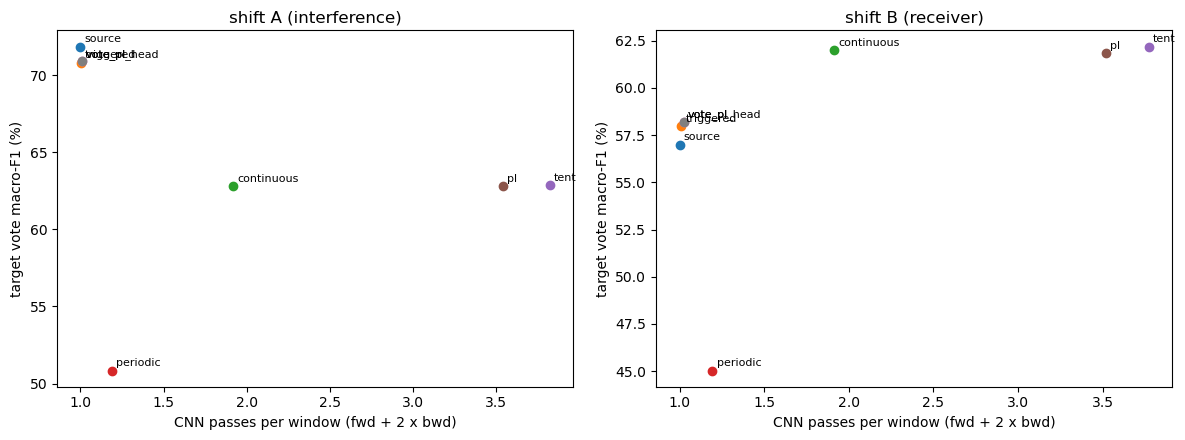

,fwd_per_window,bwd_per_window,events_per_stream,full_refreshes,restricted_refreshes,changed_per_event,wpd_macs_per_window,cnn_macs_per_forward,centring_ops_per_window,total_macs_per_window_est,note
method,,,,,,,,,,,
source,1.000,0.000,0.000,0.000,0.000,0.0,3908960,1873408,256,5.782368e+06,hardware-independent; backward = 2x forward MA...
triggered,1.007,0.000,0.253,0.129,0.124,2016.0,3908960,1873408,256,5.796024e+06,hardware-independent; backward = 2x forward MA...
continuous,1.914,0.000,174.600,0.000,0.000,2016.0,3908960,1873408,256,7.495534e+06,hardware-independent; backward = 2x forward MA...
periodic,1.192,0.000,8.333,5.564,2.769,2016.0,3908960,1873408,256,6.142476e+06,hardware-independent; backward = 2x forward MA...
tent,1.930,0.930,174.600,0.000,0.000,2016.0,3908960,1873408,256,1.100770e+07,hardware-independent; backward = 2x forward MA...
pl,1.843,0.843,174.600,0.000,0.000,409626.0,3908960,1873408,256,1.051818e+07,hardware-independent; backward = 2x forward MA...
vote_pl,1.011,0.004,0.262,0.160,0.102,411642.0,3908960,1873408,256,5.818274e+06,hardware-independent; backward = 2x forward MA...
vote_pl_head,1.011,0.004,0.262,0.160,0.102,2919.0,3908960,1873408,256,5.818274e+06,hardware-independent; backward = 2x forward MA...


In [11]:
wav = pywt.Wavelet("dmey")
L = wav.dec_len
wp = pywt.WaveletPacket(np.random.default_rng(0).normal(size=4000), "dmey", mode="symmetric", maxlevel=6)
conv_macs = sum(len(n.data) * L for lev in range(1, 7) for n in wp.get_level(lev, "natural"))
final = sum(2 * len(n.data) for n in wp.get_level(6, "natural"))
WPD_MACS = 2 * (conv_macs + final)  # I and Q channels

cnn_macs = []
hooks = [m.register_forward_hook(lambda mod, i, o: cnn_macs.append(
    o.numel() * mod.in_channels * mod.kernel_size[0] if isinstance(mod, torch.nn.Conv1d) else mod.in_features * mod.out_features))
    for m in MODELS[(0, 0)].modules() if isinstance(m, (torch.nn.Conv1d, torch.nn.Linear))]
with torch.no_grad():
    MODELS[(0, 0)](torch.zeros(1, 1, 256, device=device))
for h in hooks:
    h.remove()
CNN_MACS = sum(cnn_macs)
print(f"WPD {WPD_MACS / 1e6:.2f} M MACs/window, CNN {CNN_MACS / 1e6:.2f} M MACs/window")

ledger = runs.groupby("method", sort=False).agg(
    fwd_per_window=("fwd_per_window", "mean"), bwd_per_window=("bwd_per_window", "mean"),
    events_per_stream=("events", "mean"), full_refreshes=("full_refreshes", "mean"),
    restricted_refreshes=("restricted_refreshes", "mean"), changed_per_event=("changed_per_event", "max"))
ledger["wpd_macs_per_window"] = WPD_MACS
ledger["cnn_macs_per_forward"] = CNN_MACS
ledger["centring_ops_per_window"] = 256  # one subtraction per feature; noise windows add a 256-d EMA update
ledger["total_macs_per_window_est"] = WPD_MACS + CNN_MACS * (ledger.fwd_per_window + 2 * ledger.bwd_per_window)
ledger["note"] = "hardware-independent; backward = 2x forward MACs (estimate); E9 converts to joules"
assert len(ledger) == len(METHODS)
ledger.to_csv(os.path.join(P5, "cost_ledger.csv"))

group = runs.assign(group=np.where(runs.target.isin(SHIFT_A), "shift A (interference)", "shift B (receiver)"))
lad = group.groupby(["group", "method"], sort=False).agg(vote_f1=("vote_f1", "mean"), bwd=("bwd_per_window", "mean"),
                                                        fwd=("fwd_per_window", "mean")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
for ax, (gname, g) in zip(axes, lad.groupby("group", sort=False)):
    for _, r in g.iterrows():
        ax.scatter(r.fwd + 2 * r.bwd, 100 * r.vote_f1)
        ax.annotate(r.method, (r.fwd + 2 * r.bwd, 100 * r.vote_f1), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set_title(gname); ax.set_xlabel("CNN passes per window (fwd + 2 x bwd)"); ax.set_ylabel("target vote macro-F1 (%)")
plt.tight_layout(); fig.savefig(os.path.join(P5, "ladder.png"), dpi=120, bbox_inches="tight"); plt.show()
ledger.round(3)

## Rung 2: what the temporal vote alone adds (source-only, vote vs per-window macro-F1)

In [12]:
vg = []
for target in TARGETS:
    g = runs[(runs.target == target) & (runs.method == "source")]
    t = paired_test(g.vote_f1.values, g.window_f1.values)
    vg.append({"target": target, "window_f1": g.window_f1.mean(), "vote_f1": g.vote_f1.mean(), "diff": t["diff"],
               "ci_lo": t["ci_lo"], "ci_hi": t["ci_hi"], "p": t["p"]})
vg = pd.DataFrame(vg)
vg.to_csv(os.path.join(P5, "vote_gain.csv"), index=False)
vg.round(4)

,target,window_f1,vote_f1,diff,ci_lo,ci_hi,p
0,BLUE,0.6623,0.7611,0.0987,0.0932,0.1049,0.0000
1,WIFI,0.6599,0.7370,0.0771,0.0706,0.0835,0.0000
2,BOTH,0.5492,0.6574,0.1082,0.1003,0.1162,0.0000
3,awgn_2,0.6615,0.7392,0.0776,0.0615,0.0933,0.0000
4,awgn_3,0.5251,0.5878,0.0627,0.0461,0.0793,0.0000
5,gain_3,0.1217,0.1036,-0.0181,-0.0282,-0.0078,0.0018
6,agc_3,0.7459,0.7952,0.0493,0.0380,0.0600,0.0000
7,adc_3,0.7133,0.7807,0.0674,0.0536,0.0815,0.0000
8,tilt_4,0.3834,0.4133,0.0299,0.0177,0.0424,0.0003
